In [ ]:
import sys
from watts.plugin_dymond import ResultsDYMOND
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import json

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [180]:
from pathlib import Path
here = Path('.')
files = list(here.glob('*.json'))
inputs = list(here.glob('*.input'))
input_filepaths = [str(f.resolve()) for f in inputs]
filepaths = [str(f.resolve()) for f in files]


In [181]:
nat_assay = 0.00711
tails_assay = 0.0025
cascade = [0.1, 0.2]

In [ ]:
from watts.plugin_dymond import Parameters
from watts.plugin_dymond import ExecInfo, Results
obj = ResultsDYMOND(Parameters(), ExecInfo(1, 'dymond', 'name', 1), input_filepaths, filepaths)

In [183]:
# Get info:
# Reactor names
print(obj.reactors)

# Time info
times_dict = obj.get_times()
times = times_dict['years']
print(np.array(times))

['PWR', 'BWR', 'ALWR', 'Natrium', 'ASFR']
[1960 1961 1962 1963 1964 1965 1966 1967 1968 1969 1970 1971 1972 1973
 1974 1975 1976 1977 1978 1979 1980 1981 1982 1983 1984 1985 1986 1987
 1988 1989 1990 1991 1992 1993 1994 1995 1996 1997 1998 1999 2000 2001
 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013 2014 2015
 2016 2017 2018 2019 2020 2021 2022 2023 2024 2025 2026 2027 2028 2029
 2030 2031 2032 2033 2034 2035 2036 2037 2038 2039 2040 2041 2042 2043
 2044 2045 2046 2047 2048 2049 2050 2051 2052 2053 2054 2055 2056 2057
 2058 2059 2060 2061 2062 2063 2064 2065 2066 2067 2068 2069 2070 2071
 2072 2073 2074 2075 2076 2077 2078 2079 2080 2081 2082 2083 2084 2085
 2086 2087 2088 2089 2090 2091 2092 2093 2094 2095 2096 2097 2098 2099
 2100]


In [184]:
csv_dict = {'years': times}

In [185]:
def plot_stacked(d, ind=None, **kwargs):
    if ind is not None:
        d = {k: v[ind] for k, v in d.items()}
    df = pd.DataFrame(d, index=times)
    # Remove columns with all 0 and NaN values
    df = df.loc[:, (df != 0).any(axis=0)]
    df.plot(kind='area', stacked=True, alpha=0.5, grid=True, xlabel='Year', figsize=(8,4), **kwargs)
    plt.gca().set_axisbelow(True)

# Deployment

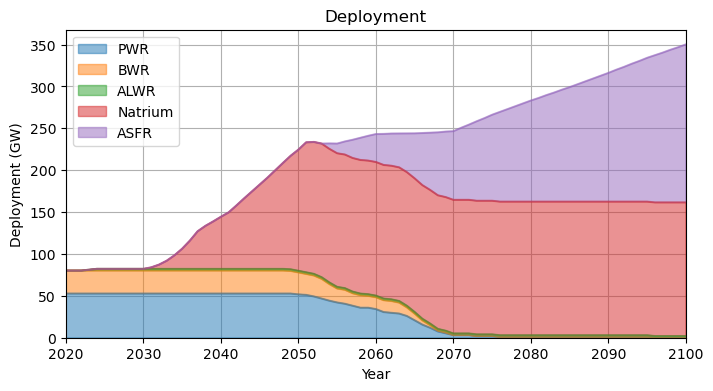

In [186]:
deployment = obj.get_deployment_dict()
plot_stacked(deployment, title='Deployment', ylabel='Deployment (GW)', xlim=(2020, 2100))

# Natural uranium

Reactor ASFR does not take traditional fuel. Returning zeros.


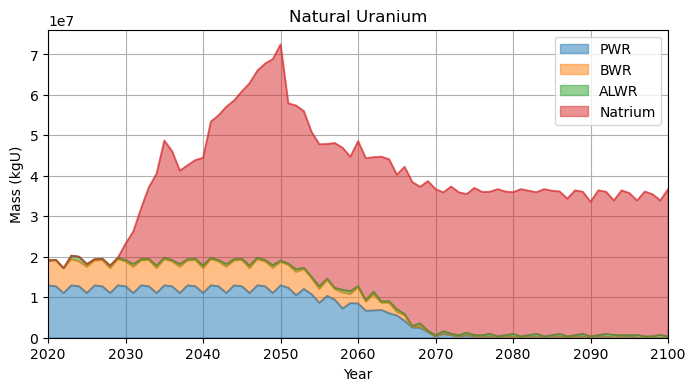

In [187]:
natlu_dict = obj.stock_fuel_natu(obj.reactors, nat_assay, tails_assay, return_sum=False)
plot_stacked(natlu_dict, title='Natural Uranium', ylabel='Mass (kgU)', xlim=(2020, 2100))
for k,v in natlu_dict.items():
    csv_dict[f'natlu_{k}'] = v
    csv_dict[f'conversion_{k}'] = v

# SWU

Reactor ASFR does not take traditional fuel. Returning zeros.


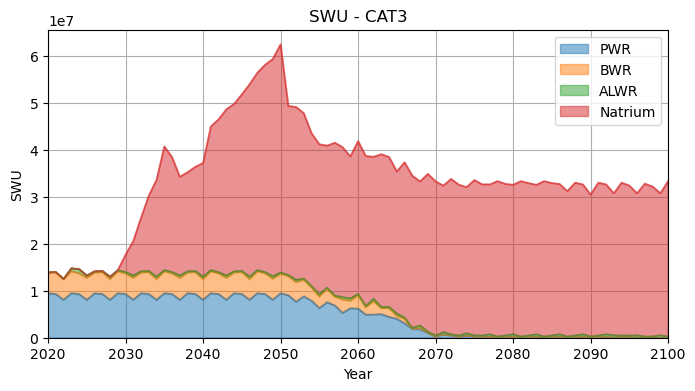

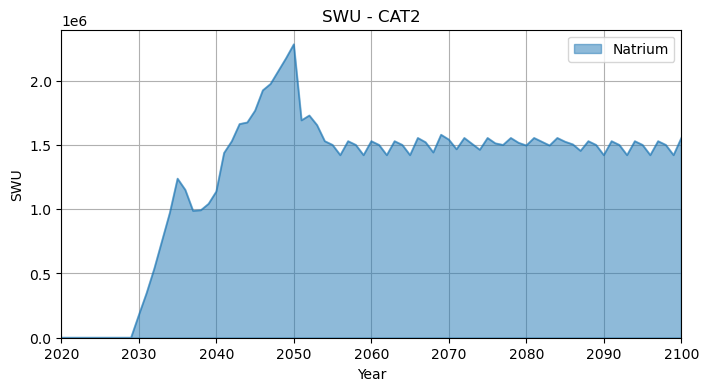

In [188]:
swu_dict = obj.stock_fuel_swu(
    natu_assay=[nat_assay, cascade[0]],
    tails_assay=[tails_assay, nat_assay],
    return_sum=False,
    split_cat=True
)
for indx, cat in enumerate(['CAT3', 'CAT2']):
    plot_stacked(swu_dict, ind=indx, title=f'SWU - {cat}', ylabel='SWU', xlim=(2020, 2100))
    for k,v in swu_dict.items():
        csv_dict[f'{cat}_SWU_{k}'] = v[indx]

# Fabrication

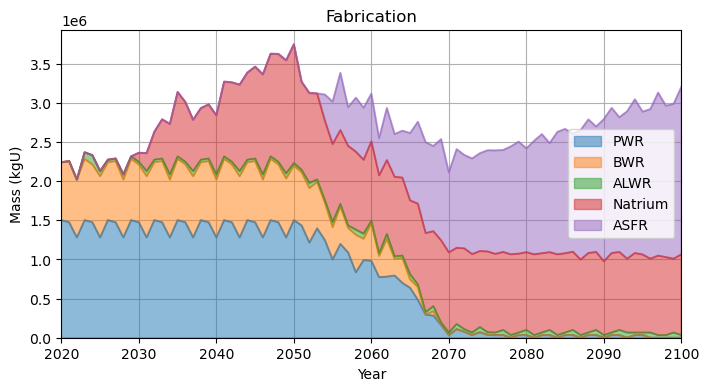

In [189]:
fab_dict = obj.stock_fuel_demand(return_sum=False)
plot_stacked(fab_dict, title='Fabrication', ylabel='Mass (kgU)', xlim=(2020, 2100))
for k,v in fab_dict.items():
    csv_dict[f'fab_{k}'] = v

# Reprocessing

In [190]:
# get reprocessing plant names
outputs = json.load(open('recycling_scenario_outputs.json'))
rep_fac_names = []
for i in outputs['input']['types']['reprocessing']:
    rep_fac_names.append(i['name'])
rep_fac_names

['reprocess_ASFR', 'reprocess_SFR']

In [191]:
obj.flows['TOTAL'].keys()

dict_keys(['PWR', 'BWR', 'ALWR', 'Natrium', 'ASFR'])

In [202]:
# TODO: DOES NOT WORK
# rep_dict = {}
# for r in rep_fac_names:
#     rep_dict[r] = obj.reprocessed_mass(r.lower()) #! why?

In [203]:
flows = json.load(open('recycling_scenario_flows.json'))
for k,v in flows['TOTAL'].items():
    print(k, len(v))

PWR 141
BWR 141
ALWR 141
Natrium 141
ASFR 141


In [210]:
# TODO: DOES NOT WORK
# for k,v in rep_dict.items():
#     #! check this!
#     #! reprocessing arrays are one longer than the time array and other fuel arrays
#     csv_dict[f'rep_{k}'] = v[:-1]
#     plt.plot(times, v[:-1], label=k)
# plt.legend()
# plt.xlabel('years')
# plt.ylabel('UNF reprocessing [kg/year]')


# Waste

In [211]:
# get wastes
#! unclear how to get HLW from reprocessing
hlw_dict = json.load(open('recycling_scenario_stocks.json'))['waste']

Text(0, 0.5, 'UNF disposed [kg/year]')

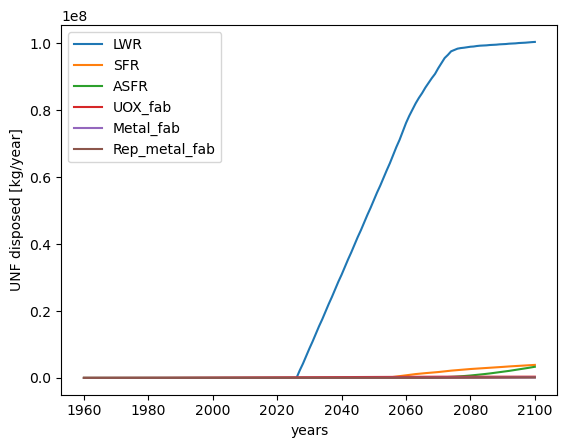

In [212]:
for k,v in hlw_dict.items():
    csv_dict[f'unf_{k}'] = v
    plt.plot(times, v, label=k)
plt.legend()
plt.xlabel('years')
plt.ylabel('UNF disposed [kg/year]')


In [213]:
import pandas as pd
df = pd.DataFrame.from_dict(csv_dict)
df = df.set_index('years')

In [214]:
df.to_csv('mass_flows.csv')